In [ ]:
pip install tensorflow

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving prediction_traffic_lstm_feature_engineering.csv to prediction_traffic_lstm_feature_engineering (2).csv


In [ ]:
df_clean = pd.read_csv("prediction_traffic_lstm_feature_engineering.csv")

# to convert the string and set as index
df_clean['date_time'] = pd.to_datetime(df_clean['date_time'])
df_clean = df_clean.set_index('date_time').sort_index()

In [ ]:
val_start = df_clean.index.get_loc("2016-10-01 09:00:00")
test_start = df_clean.index.get_loc("2017-10-02 09:00:00")
n = len(df_clean)

print(f"Validation data starts at: {val_start}")
print(f"Testing data starts at: {test_start}")
print(f"Total number of data: {n}")

Validation data starts at: 23168
Testing data starts at: 31875
Total number of data: 40575


In [ ]:
target_column = "traffic_volume"
feature_columns = [col for col in df_clean.columns if col not in ["traffic_volume", "date_time"]]

In [ ]:
# Splitting data
train = df_clean.iloc[:val_start]
val = df_clean.iloc[val_start: test_start]
test = df_clean.iloc[test_start: n]

X_train, y_train = train[feature_columns].to_numpy(), train[target_column].to_numpy()
X_val, y_val = val[feature_columns].to_numpy(), val[target_column].to_numpy()
X_test, y_test = test[feature_columns].to_numpy(), test[target_column].to_numpy()

In [ ]:
# Scaling using min-max scaler
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# for y -> it is in 1D, but min-max need 2D

X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

X_val_scaled = scaler_X.transform(X_val)
y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))

X_test_scaled = scaler_X.transform(X_test)
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

In [ ]:
# Let model refers to the last 24 hours
SEQ_LENGTH = 24

In [ ]:
def make_sequence(X, y, seq_length):
  Xs = []
  ys = []

  for i in range(seq_length, len(X)):
    Xs.append(X[i - seq_length: i])
    ys.append(y[i])

  return np.array(Xs), np.array(ys)

In [ ]:
X_train_seq, y_train_seq = make_sequence(X_train_scaled, y_train_scaled, SEQ_LENGTH)
X_val_seq, y_val_seq = make_sequence(X_val_scaled, y_val_scaled, SEQ_LENGTH)
X_test_seq, y_test_seq = make_sequence(X_test_scaled, y_test_scaled, SEQ_LENGTH)

In [ ]:
print(f"Train: {X_train_seq.shape}, {y_train_seq.shape}")
print(f"Validation: {X_val_seq.shape}, {y_val_seq.shape}")
print(f"Test: {X_test_seq.shape}, {y_test_seq.shape}")

Train: (23144, 24, 30), (23144, 1)
Validation: (8683, 24, 30), (8683, 1)
Test: (8676, 24, 30), (8676, 1)


In [ ]:
model = Sequential([
    LSTM(512, activation = "relu", return_sequences = True, input_shape = (X_train_seq.shape[1], X_train_seq.shape[2])),
    LSTM(512, activation = "relu", return_sequences = False),
    Dense(512, activation = "relu"),
    Dense(512, activation = "relu"),
    Dense(1) # Provide 1 value for prediction
])

model.compile(optimizer = "adam", loss = "mean_squared_error", metrics = ["MAE"])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 24, 512)        │     1,112,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 512)            │     2,099,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,737,089 (14.26 MB)

 Trainable params: 3,737,089 (14.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor = "val_loss",
    patience = 3
)

history = model.fit(
    X_train_seq, y_train_seq,
    validation_data = (X_val_seq, y_val_seq),
    epochs = 30,
    batch_size = 64,
    callbacks = [early_stop],
    shuffle = False
)

Epoch 1/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - MAE: 0.2006 - loss: 0.0657 - val_MAE: 0.1031 - val_loss: 0.0160
Epoch 2/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - MAE: 0.0948 - loss: 0.0174 - val_MAE: 0.0838 - val_loss: 0.0122
Epoch 3/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - MAE: 0.0830 - loss: 0.0142 - val_MAE: 0.0794 - val_loss: 0.0114
Epoch 4/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - MAE: 0.0754 - loss: 0.0122 - val_MAE: 0.0702 - val_loss: 0.0090
Epoch 5/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - MAE: 0.0684 - loss: 0.0103 - val_MAE: 0.0689 - val_loss: 0.0085
Epoch 6/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - MAE: 0.0644 - loss: 0.0092 - val_MAE: 0.0619 - val_loss: 0.0070
Epoch 7/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - MAE: 0.0609 - loss: 0.0082 - val_MAE: 0.0648 - val_loss: 0.0075
Epoch 8/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - MAE: 0.0587 - loss: 0.0078 - val_MAE: 0.0618 - val_loss: 0.0068
Epoch 9/30
362/362 ━━━━━━━━━━━━━━━━━━━━ 

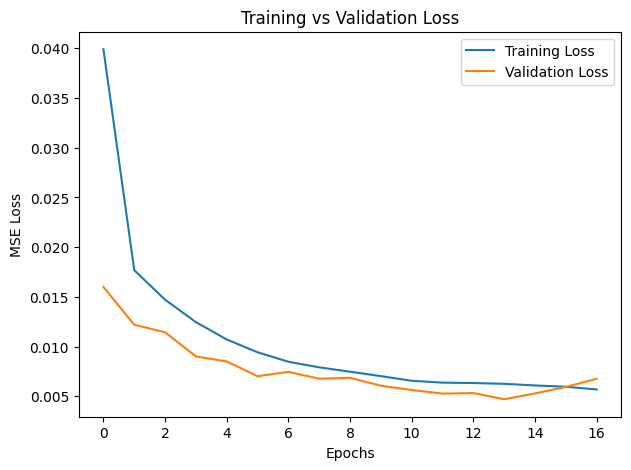

In [ ]:
plt.figure(figsize = (7, 5))
plt.plot(history.history["loss"], label = "Training Loss")
plt.plot(history.history["val_loss"], label = "Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [ ]:
# Predict scaled values
y_pred_scaled = model.predict(X_test_seq)

# Inverse scale back to real traffic volume
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_actual = scaler_y.inverse_transform(y_test_seq)

print("Predictions shape:", y_pred.shape)

272/272 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Predictions shape: (8676, 1)


In [ ]:
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
mape = mean_absolute_percentage_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

print(f"RMSE: {rmse:.5f}")
print(f"MAE: {mae:.5f}")
print(f"MAPE: {mape:.5f}")
print(f"R2 Score: {r2:.5f}")

RMSE: 618.76096
MAE: 435.42518
MAPE: 0.19607
R2 Score: 0.90202


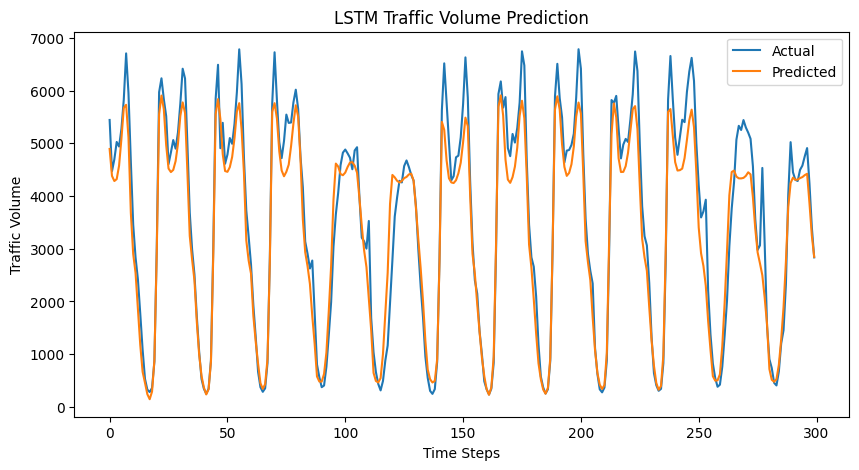

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(y_actual[:300], label='Actual')
plt.plot(y_pred[:300], label='Predicted')
plt.title('LSTM Traffic Volume Prediction')
plt.xlabel('Time Steps')
plt.ylabel('Traffic Volume')
plt.legend()
plt.show()

In [ ]:
# Saving the LSTM model
model.save("traffic_lstm_feature_engineering.keras")